### Análisis exploratorio de datos

In [1]:
#Importo la librería de pandas y leo el primer archivo, así como obtengo info del df
import pandas as pd
df1= pd.read_csv('/datasets/project_sql_result_01.csv')
print(df1.info())
print(df1.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 64 entries, 0 to 63
,Data columns (total 2 columns):
, #   Column        Non-Null Count  Dtype 
,---  ------        --------------  ----- 
, 0   company_name  64 non-null     object
, 1   trips_amount  64 non-null     int64 
,dtypes: int64(1), object(1)
,memory usage: 1.1+ KB
,None
,                      company_name  trips_amount
,0                        Flash Cab         19558
,1        Taxi Affiliation Services         11422
,2                Medallion Leasing         10367
,3                       Yellow Cab          9888
,4  Taxi Affiliation Service Yellow          9299


In [2]:
#Leo el segundo archivo y obtengo su información
df2= pd.read_csv('/datasets/project_sql_result_04.csv')
print(df2.info())
print(df2.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 94 entries, 0 to 93
,Data columns (total 2 columns):
, #   Column                 Non-Null Count  Dtype  
,---  ------                 --------------  -----  
, 0   dropoff_location_name  94 non-null     object 
, 1   average_trips          94 non-null     float64
,dtypes: float64(1), object(1)
,memory usage: 1.6+ KB
,None
,  dropoff_location_name  average_trips
,0                  Loop   10727.466667
,1           River North    9523.666667
,2         Streeterville    6664.666667
,3             West Loop    5163.666667
,4                O'Hare    2546.900000


In [3]:
#Ordeno el segundo df de forma descendente y obtengo los 10 primero barrios
nb_sorted=df2.sort_values(by='average_trips', ascending=False)
top_nb= nb_sorted.head(10)
print(top_nb)

  dropoff_location_name  average_trips
,0                  Loop   10727.466667
,1           River North    9523.666667
,2         Streeterville    6664.666667
,3             West Loop    5163.666667
,4                O'Hare    2546.900000
,5             Lake View    2420.966667
,6            Grant Park    2068.533333
,7         Museum Campus    1510.000000
,8            Gold Coast    1364.233333
,9    Sheffield & DePaul    1259.766667


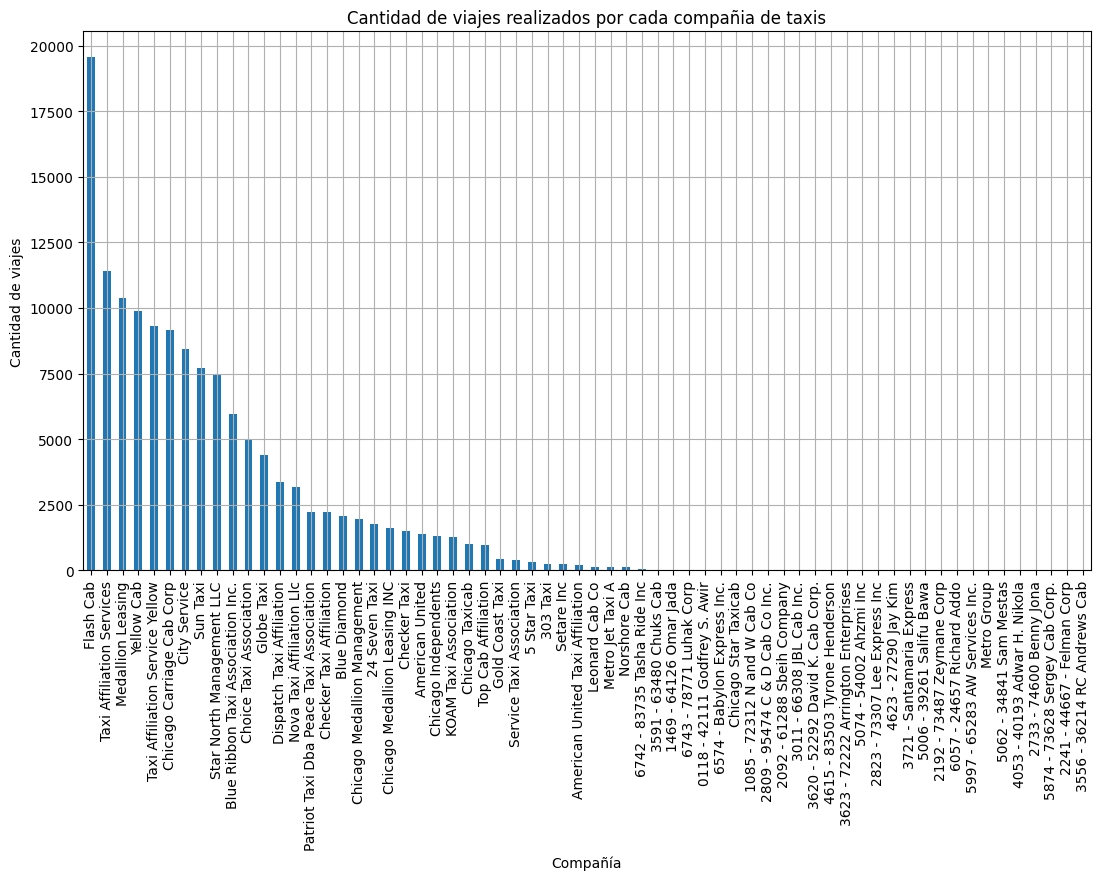

In [4]:
#Grafico el primer df para representar los viajes por compañía
from matplotlib import pyplot as plt
df1.plot(kind='bar',title='Cantidad de viajes realizados por cada compañia de taxis',
        x= 'company_name',
        y= 'trips_amount',
        xlabel= 'Compañía',
        ylabel= 'Cantidad de viajes',
        grid=True, figsize=(13,7))
plt.legend().set_visible(False)
plt.show()

La compañía de taxis que se destaca con creces sobre, el resto es Flash Cab, acumulando casi 20 mil viajes. A este le sigue Taxi Affiliation Services, con alrededor de 11500 viajes y Medallion Leasing, con poco más de 10 mil. El resto de compañías se mantiene por debajo de los 10 mil, donde 3556-36214 RC Andrews Cab es la compañía con peor cifras.

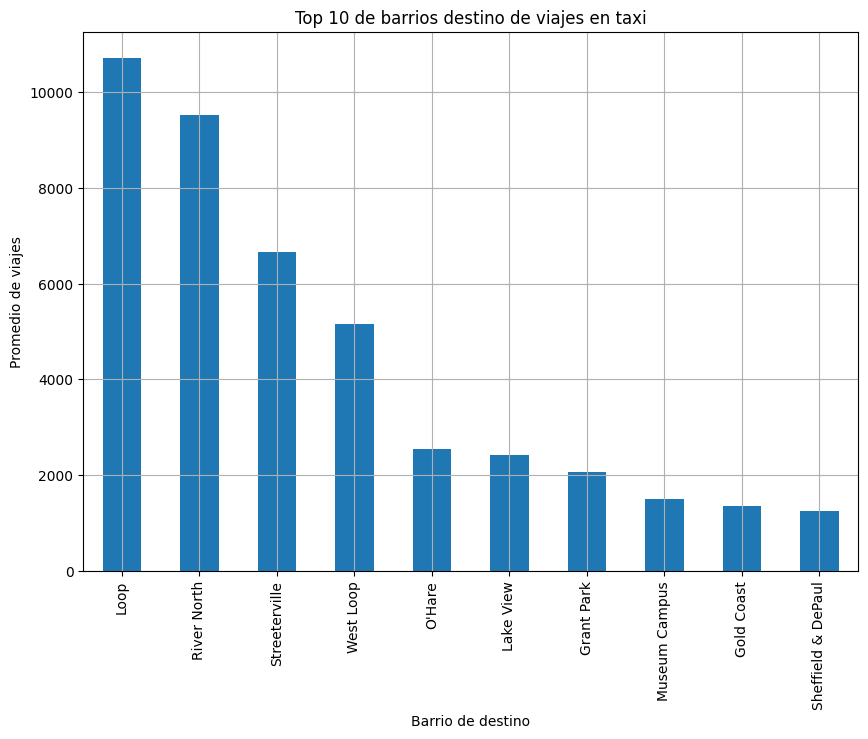

In [5]:
#Grafico el segundo df separado con los principales barrios de destino
top_nb.plot(kind='bar',title='Top 10 de barrios destino de viajes en taxi',
        x= 'dropoff_location_name',
        y= 'average_trips',
        xlabel= 'Barrio de destino',
        ylabel= 'Promedio de viajes',
        grid=True, figsize=(10,7))
plt.legend().set_visible(False)
plt.show()

Los 3 barrios con mayores viajes de destino son Loop (con más de 10 mil), River North (alrededor de 9 mil) y Streeterville (con poco menos de 7 mil). En último lugar se tiene a Sheffield & DePaul.

### Prueba de hipótesis

In [6]:
#Leo el tercer archivo y su información
df3= pd.read_csv('/datasets/project_sql_result_07.csv')
print(df3.info())
print(df3.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 1068 entries, 0 to 1067
,Data columns (total 3 columns):
, #   Column              Non-Null Count  Dtype  
,---  ------              --------------  -----  
, 0   start_ts            1068 non-null   object 
, 1   weather_conditions  1068 non-null   object 
, 2   duration_seconds    1068 non-null   float64
,dtypes: float64(1), object(2)
,memory usage: 25.2+ KB
,None
,              start_ts weather_conditions  duration_seconds
,0  2017-11-25 16:00:00               Good            2410.0
,1  2017-11-25 14:00:00               Good            1920.0
,2  2017-11-25 12:00:00               Good            1543.0
,3  2017-11-04 10:00:00               Good            2512.0
,4  2017-11-11 07:00:00               Good            1440.0


La hipotesis nula es que la duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare NO cambia los sábados lluviosos.

In [7]:
#Transformo la columna de start_ts al formato fecha y compruebo que todos los datos son del sábado
df3['start_ts']=pd.to_datetime(df3['start_ts'],format='%Y-%m-%d %H:%M:%S')
df3['Día']=df3['start_ts'].dt.weekday
print(len(df3['Día']==5))


1068


In [8]:
#Separo en dos grupos los datos, de días lluviosos y de buen clima
sabados_lluvia= df3[df3['weather_conditions']=='Bad']
sabados_buenclima= df3[df3['weather_conditions']=='Good']
print(len(sabados_lluvia))
print(len(sabados_buenclima))

180
,888


In [9]:
#Compruebo la varianza y la media de ambos grupos de datos antes de hacer la prueba de hipotesis
import numpy as np
duracion_lluvia= sabados_lluvia['duration_seconds']
duracion_buen_clima= sabados_buenclima['duration_seconds']
var_lluvia= np.var(duracion_lluvia)
var_buenc= np.var(duracion_buen_clima)
print('La varianza de los sábados lluviosos es:', var_lluvia)
print('La varianza de los sábados con buen clima es:', var_buenc)
print('Duración promedio sábados lluviosos:', duracion_lluvia.mean())
print('Duración promedio sábados buen clima:', duracion_buen_clima.mean())

La varianza de los sábados lluviosos es: 517403.56330246915
,La varianza de los sábados con buen clima es: 575732.9308497686
,Duración promedio sábados lluviosos: 2427.2055555555557
,Duración promedio sábados buen clima: 1999.6756756756756


In [10]:
#Hago la prueba de hipótesis
from scipy import stats as st
alpha= 0.05
results=st.ttest_ind(duracion_lluvia,duracion_buen_clima,equal_var= False)
print('Valor p:',results.pvalue)
if results.pvalue < alpha:
    print('Rechazamos la hipótesis nula: la duración promedio de los viajes sí es diferente los sábados lluviosos.')
else: 
    print('No podemos rechazar la hipótesis nula: la duración promedio de los viajes no cambia los sábados lluviosos.')

Valor p: 6.738994326108734e-12
,Rechazamos la hipótesis nula: la duración promedio de los viajes sí es diferente los sábados lluviosos.


La hipótesis nula siempre implica que no hay diferencia entre los datos comparados, mientras la alternativa es que sí la hay. El valor p es extremadamente inferior al valor alfa, por lo que se rechaza la hipótesis nula. 
Aunque cabe destacar que hay una diferencia muy grande entre el número de datos de días lluviosos (180) y días con buen clima (888).